# **Libraries**
---
The libraries used in the regression workflow are imported: execution time measurement, visualization, data manipulation, synthetic data generation, hyperparameter search with cross-validation, the Random Forest regression model, and the RMSE metric.

The `time` library is central to this notebook, because the objective is not only to compare the error of the models but also the **computational cost** of each hyperparameter selection strategy.

In [1]:
# Utils
# ==============================================================================
import warnings
import time

# Plot
# ==============================================================================
import matplotlib.pyplot as plt
import seaborn as sns

# Data
# ==============================================================================
import numpy as np
import pandas as pd
from sklearn.datasets import make_friedman1

# Model
# ==============================================================================
from sklearn.model_selection import (
    train_test_split,
    ParameterGrid,
    GridSearchCV
)

from sklearn.ensemble import RandomForestRegressor

# Metrics
# ==============================================================================
from sklearn.metrics import root_mean_squared_error

# **Info**
---

**@By:** Steven Bernal

**@Nickname:** Kaiziferr

**@Git:** https://github.com/Kaiziferr

# **Configuration**
---
The global configuration of the run is defined. Warning messages are suppressed to produce cleaner outputs, the seaborn `tab10` color palette is defined for the comparison plots, and the random seed `12354` is set. This seed is used in data generation, the data split, and all models to ensure reproducibility.

In [2]:
warnings.simplefilter("ignore")
paleta = sns.color_palette("tab10").as_hex()
random_seed = 12354

# **Data context**
---
**Project context**

The objective of this project is to demonstrate the use of the **OOB score** (out-of-bag score) in Random Forest as an alternative to cross-validation for hyperparameter selection. In a Random Forest, each tree is trained on a bootstrap sample of the training set, and the observations left out of that sample (out-of-bag) make it possible to estimate model performance without reserving additional folds.

**Data source**

A synthetic dataset was chosen because it provides a controlled and educational environment, specifically designed to explain the use of the OOB score in Random Forest hyperparameter selection.

Working with real-world datasets usually requires considerable preprocessing effort, such as data cleaning, handling missing values, correcting inconsistencies, and transforming variables. Although these steps are essential in any data science workflow, they are outside the scope of this discussion.

**Objectives**

- Select the hyperparameters of a Random Forest regressor with GridSearchCV and 5-fold cross-validation.
- Select the hyperparameters with the OOB score, first with the default R² and then with a custom metric (RMSE).
- Compare both strategies on the test set and in terms of **computational cost**, distinguishing the time of each fit from the total search time.

# **Regression**
---

## **Data**
---
The scikit-learn make_friedman1 function is used to generate a synthetic dataset with a nonlinear relationship between the predictor variables and the target variable:

- `1000` observations and 8 predictor variables are generated, with values uniformly distributed between 0 and 1.
- According to the scikit-learn documentation, the target variable depends only on the first 5 variables, combined through a sine function, a quadratic term, and linear terms. The remaining 3 variables are unrelated to the target variable.
- Gaussian noise with a standard deviation of 1.8 is added to the target variable. This noise cannot be predicted, so no model can reach zero error on new data.

In [3]:
X, y = make_friedman1(
    n_samples=1000,
    n_features=8,
    noise=1.8,
    random_state=random_seed
)

The first rows of the predictor variables are displayed to verify their structure.

In [4]:
pd.DataFrame(X).head()

,0,1,2,3,4,5,6,7
0,0.551963,0.109711,0.029752,0.428018,0.560191,0.794667,0.465564,0.345875
1,0.337109,0.204982,0.450691,0.149433,0.784783,0.296252,0.869173,0.452800
2,0.211150,0.904876,0.333836,0.786745,0.495321,0.447385,0.820702,0.371697
3,0.471441,0.021436,0.237610,0.709758,0.575986,0.411255,0.712220,0.164222
4,0.552286,0.846666,0.785294,0.980033,0.863304,0.053508,0.088855,0.508065


The table shows the first five observations of the 8 predictor variables, identified by the indices 0 to 7. All values are between 0 and 1, as expected from the uniform distribution of make_friedman1. The variables have no names because they are synthetic. Columns 5, 6, and 7 belong to the variables that do not influence the target variable, although they cannot be distinguished from the others at first sight. This is precisely one of the tasks of the model: learning which variables carry information.

## **Data split**
---
The dataset is split into training and test sets with train_test_split. 80% of the observations (800) are assigned to the training set, and the remaining 20% (200) are reserved for the final evaluation.

Unlike other workflows, no separate validation set is created: GridSearchCV cross-validation and the OOB score obtain their performance estimates from the training set itself. The test set is not involved in either search.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    train_size = 0.8,
    random_state = random_seed
)

## **Model**
---
### **Search with cross-validation (GridSearchCV)**

Cross-validation makes it possible to estimate the performance of each Random Forest configuration, but it can be expensive, because each configuration is trained several times. A search space was defined with the following hyperparameters:

- **n_estimators:** number of trees in the forest.
- **criterion:** function used to measure the quality of each split (squared_error or absolute_error).
- **min_samples_split:** minimum number of observations required to split a node.
- **min_samples_leaf:** minimum number of observations in each leaf.
- **max_features:** number of variables considered at each split.
- **max_depth:** maximum depth of each tree.

The same search space is later used with the OOB score, so both strategies evaluate exactly the same configurations.

In [6]:
dict_params = ParameterGrid(
    {
        "n_estimators": [100, 150, 200],
        "criterion": ["squared_error", "absolute_error"],
        "min_samples_split": [2, 4, 8],
        "min_samples_leaf": [1, 2, 4, 8],
        "max_features": [0.75, "sqrt", "log2"],
        "max_depth": [None, 20, 30],
    }
)

The search space combines 3 values of n_estimators, 2 of criterion, 3 of min_samples_split, 4 of min_samples_leaf, 3 of max_features, and 3 of max_depth, which results in `648 configurations`.

5-fold cross-validation is used (cv=5). With 800 training observations, each fold trains the model with about 640 observations and evaluates it with about 160. Therefore, each configuration is trained 5 times, and the full search performs 648 × 5 = `3,240 fits`, plus a final fit with the best configuration.

The start time is recorded to measure the total search time.

In [7]:
start_time = time.time()

GridSearchCV evaluates the 648 configurations with 5-fold cross-validation and uses RMSE as the metric (scoring='neg_root_mean_squared_error'). scikit-learn returns the RMSE with a negative sign because its selection criteria always maximize, so the highest value corresponds to the lowest error. With refit=True, the best configuration is retrained on the full training set, and with return_train_score=True the training error of each configuration is also recorded.

The estimator uses n_jobs=-1 to train the trees of each forest in parallel on all available cores.

In [8]:
grid = GridSearchCV(
    estimator = RandomForestRegressor(
        n_jobs=-1,
        random_state=random_seed
    ),
    cv = 5,
    param_grid = dict_params.param_grid[0],
    scoring = "neg_root_mean_squared_error",
    refit =  True,
    verbose = 0,
    return_train_score = True

)
grid.fit(X_train, y_train)

,estimator,RandomForestR...m_state=12354)
,param_grid,"{'criterion': ['squared_error', 'absolute_error'], 'max_depth': [None, 20, ...], 'max_features': [0.75, 'sqrt', ...], 'min_samples_leaf': [1, 2, ...], ...}"
,scoring,'neg_root_mean_squared_error'
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,True
,n_estimators,200


In [9]:
end_time = time.time()

The total search time is calculated and stored for the later comparison with the OOB score.

In [10]:
grid_time = end_time - start_time
print(f"Execution time: {grid_time:.5f} seconds")

Execution time: 1140.36357 seconds


The GridSearchCV search took `1,140.36 seconds`, about **19.0 minutes**. This time is a direct consequence of the number of models that are trained:

- 3,240 cross-validation fits are performed (648 configurations × 5 folds), plus a final fit with the best configuration.
- Each fit is a complete forest. Because each n_estimators value (100, 150, and 200) appears in 216 configurations, cross-validation trains 5 × 216 × (100 + 150 + 200) = **486,000 trees**, plus the 200 trees of the final refit.

Although n_jobs=-1 distributes the trees of each forest across all available cores, the training volume remains high. This value is the cost reference against which the OOB score is compared later.

The search results (grid.cv_results_) are converted into a table, and the four configurations with the lowest mean cross-validation RMSE are displayed. The mean_test_score and mean_train_score columns contain the mean RMSE (with a negative sign) on the validation and training folds, and the std_ columns indicate their standard deviation across folds.

In [11]:
results = pd.DataFrame(grid.cv_results_)
results.filter(regex = '(param.*|mean_t|std_t)') \
    .drop(columns = 'params') \
    .sort_values(['mean_test_score', 'mean_train_score'], ascending = False) \
    .head(4)

,param_criterion,param_max_depth,param_max_features,param_min_samples_leaf,param_min_samples_split,param_n_estimators,mean_test_score,std_test_score,mean_train_score,std_train_score
77,squared_error,None,log2,1,4,200,-2.550536,0.151563,-1.086777,0.013514
293,squared_error,30,log2,1,4,200,-2.550536,0.151563,-1.086777,0.013514
185,squared_error,20,log2,1,4,200,-2.551328,0.151290,-1.086895,0.013175
181,squared_error,20,log2,1,2,150,-2.553251,0.156306,-0.956545,0.009324


The table shows the four configurations with the lowest mean cross-validation RMSE (scores are shown with a negative sign):

- The best configuration (index 77) obtains a mean validation RMSE of `2.5505`, with a standard deviation of 0.1516 across folds. The four configurations range from 2.5505 to 2.5533, a difference of only 0.003, so their validation performance is practically equivalent.
- All of them use squared_error as the criterion, log2 for max_features, and min_samples_leaf=1. The first three use 200 trees and min_samples_split=4. The fourth (index 181) uses 150 trees and min_samples_split=2.
- The rows with max_depth=None and max_depth=30 are identical, and max_depth=20 barely changes the RMSE (2.5513). The trees do not grow beyond that depth with these data, so the limit has no practical effect.
- There is a large gap between training and validation. The best configuration has a training RMSE of 1.0868 compared with 2.5505 on validation: the validation error is 134.7% higher. The fourth configuration has an even lower training RMSE (0.9565) without improving validation (2.5533). The additional flexibility of min_samples_split=2 fits the training data more closely but does not improve generalization.

Overall, several configurations provide almost identical validation performance with very different levels of fit to the training data. Selecting only by the lowest validation RMSE may favor a more flexible model without a real benefit on new data.

The best model found by GridSearchCV, already retrained on the full training set, is stored.

In [12]:
best_model_grid = grid.best_estimator_

The selected model is evaluated on the test set with RMSE. This result measures the expected error on observations that were not involved in the hyperparameter search or in training.

In [13]:
y_predict = best_model_grid.predict(X_test)
root_mean_squared_error(y_test, y_predict)

2.3854479050772537

The model selected by GridSearchCV obtains a test RMSE of `2.3854`. On average, its predictions deviate by about 2.39 units from the actual value on observations that were involved neither in training nor in hyperparameter selection.

The test RMSE is lower than the mean cross-validation RMSE (2.5505). This difference does not indicate a problem: cross-validation averages five folds of about 160 observations, while the test result comes from a single sample of 200 observations, and differences between both values may be due to the specific observations in each split. For the same reason, the test result does not show that the model is free from overfitting. It must be interpreted together with the gap between training and validation observed in the previous table.

### **Selection by relative train-validation gap**

The configuration with the lowest validation RMSE is not necessarily the most appropriate if it reaches that result by fitting the training data excessively. As an additional criterion, the **relative gap** of each configuration is calculated:

relative gap (%) = (validation RMSE − training RMSE) / training RMSE × 100

In the code, the scores have a negative sign, so the expression (mean_train_score − mean_test_score) / (−mean_train_score) is equivalent to the formula above. A smaller gap indicates that the validation error is closer to the training error.

In [14]:
results['relative_gap_%'] = (
    (results['mean_train_score'] - results['mean_test_score'])
    / (-results['mean_train_score'])
) * 100

The four configurations with the smallest relative gap are displayed.

In [15]:
results.filter(regex='(param.*|mean_t|std_t|relative_gap_)') \
    .drop(columns='params', errors='ignore') \
    .sort_values('relative_gap_%', ascending=True) \
    .head(4)

,param_criterion,param_max_depth,param_max_features,param_min_samples_leaf,param_min_samples_split,param_n_estimators,mean_test_score,std_test_score,mean_train_score,std_train_score,relative_gap_%
606,absolute_error,30,sqrt,8,4,100,-2.987924,0.130092,-2.474523,0.01193,20.747486
609,absolute_error,30,sqrt,8,8,100,-2.987924,0.130092,-2.474523,0.01193,20.747486
390,absolute_error,None,sqrt,8,4,100,-2.987924,0.130092,-2.474523,0.01193,20.747486
393,absolute_error,None,sqrt,8,8,100,-2.987924,0.130092,-2.474523,0.01193,20.747486


The table shows the four configurations with the smallest relative gap. All four obtain exactly the same values: a validation RMSE of `2.9879`, a training RMSE of 2.4745, and a relative gap of **20.75%**. In other words, the validation error is about 21% higher than the training error.

- All of them share absolute_error as the criterion, sqrt for max_features, min_samples_leaf=8, and 100 trees. These values restrict the complexity of each tree: they require more observations per leaf and consider fewer variables at each split.
- The configurations differ in max_depth and min_samples_split but obtain the same results. With min_samples_leaf=8, those parameters no longer influence the structure of the trees. Because of this tie, the order of the rows in the table may change between runs; the indices shown in this run are 606, 609, 390, and 393.
- Compared with the configuration with the lowest validation RMSE, the gap drops from 134.7% to 20.75%, but the validation RMSE rises from 2.5505 to 2.9879 (+0.44).

A smaller gap indicates that the validation error is closer to the training error, but it does not imply better performance on its own: it only describes the distance between both errors.

A Random Forest is trained with one of the configurations tied for the smallest relative gap: absolute_error, sqrt, min_samples_leaf=8, min_samples_split=8, max_depth=30, and 100 trees (index 609 of the search results, with the same scores as the rows shown). It is then evaluated on the test set to compare it with the model with the lowest validation RMSE.

In [16]:
modelo_gab = RandomForestRegressor(
    random_state=random_seed,
    criterion = 'absolute_error',
    max_depth=  30,
    max_features=  'sqrt',
    min_samples_leaf=  8,
    min_samples_split=  8,
    n_estimators= 100
)
modelo_gab.fit(X_train, y_train)

,n_estimators,100
,criterion,'absolute_error'
,max_depth,30
,min_samples_split,8
,min_samples_leaf,8
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [17]:
y_predict = modelo_gab.predict(X_test)
root_mean_squared_error(y_test, y_predict)

2.799236870202072

The model selected by the smallest relative gap obtains a test RMSE of `2.7992`, compared with 2.3854 for the model with the lowest validation RMSE: an error 0.41 units higher (+17.3%).

Its greater stability between training and validation did not translate into better predictions on new data. The constraints that reduced the gap (leaves with at least 8 observations and fewer variables per split) also reduced the ability of the model to capture the nonlinear relationship in the data. The relative gap is useful as an overfitting diagnostic, but not as a standalone selection criterion. In addition, this approach required the same expensive GridSearchCV search.

### **Search with OOB score (R²)**

In a Random Forest, each tree is trained on a bootstrap sample: a sample of the same size as the training set, drawn with replacement. On average, about 63% of the distinct observations enter each sample, and the remaining 37% are left out (out-of-bag). Each observation can be predicted by the trees that did not use it, and these predictions are used to calculate the **OOB score**, an estimate of performance on unseen data that does not require training the model several times.

- To calculate it, the oob_score parameter must be set to True.
- In regression, the default metric is the coefficient of determination (R²).

The code goes through the same 648 GridSearchCV configurations. For each one, it trains a Random Forest with oob_score=True on the training set (800 observations), stores its OOB R², and measures the time of that fit (fit_time). The total time of the loop is also measured.

In [18]:
start_time = time.time()
result = {
    'params': [],
    'oob_r2': [],
    'fit_time': []
}

for params in dict_params:  
    model_oobscore = RandomForestRegressor(
        oob_score=True,
        n_jobs=-1,
        random_state=random_seed,
        **params
    )

    start_time_f = time.time()
    model_oobscore.fit(X_train, y_train)
    end_time_f = time.time()

    result['params'].append(params)
    result['oob_r2'].append(model_oobscore.oob_score_)
    result['fit_time'].append(end_time_f - start_time_f)

end_time = time.time()

The total time of the OOB R² search is calculated and stored.

In [19]:
oob_r2_time = end_time - start_time
print(f"Execution time: {oob_r2_time:.5f} seconds")

Execution time: 244.64295 seconds


The OOB R² search took `244.64 seconds`, about **4.1 minutes**, compared with 1,140.36 seconds for GridSearchCV: **78.5% less time** to evaluate the same 648 configurations.

The difference is explained by the number of fits. Each configuration is trained only once, and its performance is estimated with the observations that each tree left out of its bootstrap sample, without retraining it on 5 folds. The final comparison section analyzes whether each individual OOB fit is faster or slower than a GridSearchCV fold.

The result is converted into a table, the hyperparameters are split into columns, and the configurations are sorted from highest to lowest OOB R².

In [20]:
results_score = pd.DataFrame(result)
results_score = pd.concat(
    [results_score, results_score['params'].apply(pd.Series)], axis=1
)
results_score = results_score.drop(columns = 'params')
results_score = results_score.sort_values('oob_r2', ascending=False)
results_score.head(4)

,oob_r2,fit_time,criterion,max_depth,max_features,min_samples_leaf,min_samples_split,n_estimators
74,0.775295,0.349078,squared_error,NaN,log2,1,2,200
290,0.775295,0.345455,squared_error,30.0,log2,1,2,200
182,0.774828,0.353782,squared_error,20.0,log2,1,2,200
185,0.772709,0.343405,squared_error,20.0,log2,1,4,200


The table shows the four configurations with the highest OOB R², together with the time of their fit (fit_time):

- The best configuration (index 74) reaches an OOB R² of `0.7753`: according to its out-of-bag predictions, the model explains about 77.5% of the variability of the target variable.
- The four configurations use squared_error, log2, min_samples_leaf=1, and 200 trees, the same pattern observed in GridSearchCV. The difference is that OOB prefers min_samples_split=2, while GridSearchCV chose min_samples_split=4 (index 77).
- As in GridSearchCV, max_depth=None and max_depth=30 produce identical results.
- Each of these fits took between 0.34 and 0.35 seconds.

The Random Forest is trained with the configuration with the highest OOB R² (index 74) and evaluated on the test set.

In [21]:
model_r = RandomForestRegressor(
        oob_score=True,
        n_jobs=-1,
        random_state=random_seed,
        criterion = "squared_error",
        max_depth = None,
        max_features = "log2",
        min_samples_leaf = 1,
        min_samples_split = 2,
        n_estimators = 200
    )

model_r.fit(X_train, y_train)

,n_estimators,200
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'log2'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,True


In [22]:
y_predict = model_r.predict(X_test)
root_mean_squared_error(y_test, y_predict)

2.423062850013381

The model selected with OOB R² obtains a test RMSE of `2.4231`, only 0.04 units more than the GridSearchCV model (2.3854), that is, 1.6% more error, with 78.5% less search time.

Compared with the model selected by the relative gap (2.7992), the OOB model has an error 0.38 units lower. In this problem, the OOB score provides a favorable balance between computational cost and predictive performance.

### **OOB score with a custom metric (RMSE)**

The oob_score parameter also accepts a function with the form metric(y_true, y_pred). This makes it possible to use an error metric as the OOB score instead of the default R². A function that calculates RMSE is defined, the same metric used in GridSearchCV and in the test evaluation, so that selection and evaluation use the same criterion.

R² indicates the proportion of the variability of the target variable that the model explains, but it does not directly express the magnitude of the error. RMSE, in contrast, measures the typical prediction error in the units of the target variable and penalizes large errors more heavily.

In [23]:
def metrica_oob_score(y, y_predict, **kwargs):
  score = root_mean_squared_error(y, y_predict, **kwargs)
  return score

The 648 configurations are evaluated again, now with the RMSE function as the OOB score. For each configuration, the OOB RMSE and the time of its fit (fit_time) are stored. These times are the ones compared later with GridSearchCV, because both searches use the same metric.

The results dictionary is initialized in the same cell as the loop, so running the cell again does not duplicate the records.

In [24]:
start_time = time.time()
resultados = {
    'params': [],
    'squared_error': [],
    'fit_time': []
}

for params in dict_params:
  model_oobscore = RandomForestRegressor(
      oob_score       = metrica_oob_score,
      n_jobs          =-1,
      random_state    = random_seed,
      **params
  )

  start_time_f = time.time()
  model_oobscore.fit(X_train, y_train)
  end_time_f = time.time()
  resultados['params'].append(params)
  resultados['squared_error'].append(model_oobscore.oob_score_)
  resultados['fit_time'].append(end_time_f - start_time_f)
end_time = time.time()

The total time of the OOB RMSE search is calculated and stored.

In [25]:
oob_rmse_time = end_time - start_time
print(f"Execution time: {oob_rmse_time:.5f} seconds")

Execution time: 245.98345 seconds


The OOB RMSE search took `245.98 seconds`, practically the same as the OOB R² search (244.64 seconds). Calculating a custom metric does not add a noticeable cost, because computing the OOB score is very small compared with training the trees. Compared with GridSearchCV (1,140.36 seconds), the time reduction is 78.4%.

The result is converted into a table, and the configurations are sorted from lowest to highest OOB RMSE.

In [26]:
resultados_scores = pd.DataFrame(resultados)
resultados_scores = pd.concat(
    [resultados_scores, resultados_scores['params'].apply(pd.Series)], axis=1)

resultados_scores = resultados_scores.drop(columns = 'params')
resultados_scores = resultados_scores.sort_values('squared_error', ascending=True)
resultados_scores.head(4)

,squared_error,fit_time,criterion,max_depth,max_features,min_samples_leaf,min_samples_split,n_estimators
74,2.521994,0.491977,squared_error,NaN,log2,1,2,200
290,2.521994,0.346414,squared_error,30.0,log2,1,2,200
182,2.524613,0.340607,squared_error,20.0,log2,1,2,200
185,2.536465,0.328096,squared_error,20.0,log2,1,4,200


The table shows the four configurations with the lowest OOB RMSE. The best one (index 74) obtains an OOB RMSE of `2.5220`, very close to the best mean cross-validation RMSE of GridSearchCV (2.5505).

The four configurations and their order are exactly the same as with OOB R². This is not a coincidence: the OOB R² is calculated as 1 − MSE / variance of y, with the same out-of-bag predictions and the same training target variable. Therefore, R² is a monotonic transformation of RMSE, and both metrics always rank the configurations in the same way. In this case, switching from R² to RMSE changes the scale of the score, which is now expressed in the units of the target variable and directly comparable with the GridSearchCV RMSE, but it does not change the selection.

The Random Forest is trained with the configuration with the lowest OOB RMSE and evaluated on the test set.

In [27]:
model_oob = RandomForestRegressor(
        oob_score=metrica_oob_score,
        n_jobs=-1,
        random_state=random_seed,
        criterion = "squared_error",
        max_depth = None,
        max_features = "log2",
        min_samples_leaf = 1,
        min_samples_split=2,
        n_estimators = 200
    )

model_oob.fit(X_train, y_train)

,n_estimators,200
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'log2'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,<function met...x7fc1b30a4dc0>


In [28]:
y_predict = model_oob.predict(X_test)
root_mean_squared_error(y_test, y_predict)

2.423062850013381

The test RMSE is `2.4231`, identical to that of the model selected with OOB R². This is the expected result for two reasons:

- The OOB score metric does not change training. With the same hyperparameters, the same data, and the same seed, the same trees are generated, and therefore the same predictions on X_test.
- OOB R² and OOB RMSE selected the same configuration, because they rank the configurations in the same way.

The value of the custom metric lies in interpretation: the OOB RMSE is expressed in the same units as the cross-validation RMSE and the test RMSE, which makes it possible to compare both strategies directly in the next section.

### **Cost and performance comparison between GridSearchCV and OOB**

Both strategies evaluated the same 648 configurations, but in different ways:

- **GridSearchCV:** trains each configuration 5 times, once per fold, with about 640 observations, and its result per configuration is the **mean** of the 5 validation RMSE values.
- **OOB:** trains each configuration only once, with the 800 training observations, and its result per configuration is **a single** RMSE calculated from the out-of-bag predictions.

To compare them under equivalent conditions, a table with one row per configuration is built. GridSearchCV does not measure the time of each complete configuration, but the mean time per fold: mean_fit_time (training) and mean_score_time (validation score calculation). The time of one fold is obtained as the sum of both, and the time of a complete configuration as 5 times that value. In OOB, fit_time already includes training and the OOB score calculation.

The cell also checks that the rows of both searches correspond to the same configurations in the same order, a necessary condition for comparing them one by one.

**Outlier time control**

The time of each fit is measured with time.time(), which records the actual elapsed time. Therefore, a brief system pause (for example, another process using the cores) can lengthen a fit without its configuration being the cause. This happened in a previous run of this notebook: one OOB fit took about 46 seconds, when the median was about 0.32 seconds and the rest of the fits stayed below 1.5 seconds. That single value stretched the scale of plot 1 until the other configurations were compressed, and it raised the mean OOB time.

To prevent such a situation from distorting the comparison, the cell flags a configuration as an outlier when its OOB fit or its GridSearchCV fold takes **more than 10 times the median** of its strategy:

- **The median is used** as the reference because, unlike the mean, it is not shifted by an extreme value.
- **The factor of 10 is a heuristic threshold**, not a statistical standard. It was deliberately set high to detect only clear measurement failures. With a median of about 0.3 seconds, the threshold is about 3 seconds, far above the legitimately expensive configurations (absolute_error with 200 trees, which take about 1 second per OOB fit).
- **The 1.5 × interquartile range rule** of box plots is not used, because it would flag precisely those expensive configurations, which are real and are part of what is being compared.
- **The same rule is applied to both strategies**, so neither one is favored.

Flagged configurations are excluded only from plot 1 (comparison_plot table), and the cell prints how many there are and which ones. The summary table, plot 2, and the total times always use the 648 configurations.

In [29]:
# Build a per-configuration table with the cost and error of both strategies
grid_res = pd.DataFrame(grid.cv_results_)
oob_res = pd.DataFrame(resultados)
n_folds = grid.n_splits_

# Both searches must contain the same configurations in the same order
assert grid_res['params'].tolist() == oob_res['params'].tolist()

comparison = pd.DataFrame({
    'criterion': grid_res['param_criterion'],
    'n_estimators': grid_res['param_n_estimators'].astype(int),
    'grid_rmse_cv': -grid_res['mean_test_score'],
    'grid_fold_time': grid_res['mean_fit_time'] + grid_res['mean_score_time'],
    'oob_rmse': oob_res['squared_error'],
    'oob_time': oob_res['fit_time'],
})
comparison['grid_config_time'] = n_folds * comparison['grid_fold_time']
comparison['time_ratio'] = comparison['grid_config_time'] / comparison['oob_time']

# Summary of the computational cost of each strategy
cost_summary = pd.DataFrame({
    'fits': [len(comparison) * n_folds + 1, len(comparison)],
    'mean time per fit (s)': [comparison['grid_fold_time'].mean(), comparison['oob_time'].mean()],
    'mean time per configuration (s)': [comparison['grid_config_time'].mean(), comparison['oob_time'].mean()],
    'sum of fits (s)': [comparison['grid_config_time'].sum() + grid.refit_time_, comparison['oob_time'].sum()],
    'measured time (s)': [grid_time, oob_rmse_time],
}, index=['GridSearchCV', 'OOB (RMSE)']).round(4)

# Flag fits that took more than 10 times the median time of their strategy
outlier_factor = 10
outliers = comparison.index[
    (comparison['oob_time'] > outlier_factor * comparison['oob_time'].median())
    | (comparison['grid_fold_time'] > outlier_factor * comparison['grid_fold_time'].median())
]
comparison_plot = comparison.drop(index=outliers)
print(f'Configurations with outlier times: {len(outliers)}')
print(comparison.loc[outliers, ['criterion', 'n_estimators', 'grid_fold_time', 'oob_time']].round(4))
print(f"Mean OOB time per fit without outliers: {comparison_plot['oob_time'].mean():.4f} s")
print(f"Mean GridSearchCV time per fold without outliers: {comparison_plot['grid_fold_time'].mean():.4f} s")
cost_summary

Configurations with outlier times: 1
        criterion  n_estimators  grid_fold_time  oob_time
87  squared_error           100           3.295    0.2088
Mean OOB time per fit without outliers: 0.3797 s
Mean GridSearchCV time per fold without outliers: 0.3111 s


,fits,mean time per fit (s),mean time per configuration (s),sum of fits (s),measured time (s)
GridSearchCV,3241,0.3157,1.5784,1023.0604,1140.3636
OOB (RMSE),648,0.3794,0.3794,245.8534,245.9835


The cell confirms that the 648 configurations are in the same order in both searches and detects **one configuration with an outlier time** (index 87: squared_error, max_features=log2, min_samples_leaf=2, min_samples_split=8, and 100 trees). Its mean GridSearchCV fold time was 3.30 seconds, about 11.5 times the median fold time (0.29 s), while the same configuration took only 0.21 seconds in OOB. Configurations with squared_error and 100 trees are among the cheapest in the search space, so this time is not explained by its hyperparameters and is treated as a measurement outlier, such as a brief system pause. It is excluded only from plot 1; the summary table, plot 2, and the total times keep the 648 configurations. Without it, the mean time per GridSearchCV fold would be 0.3111 seconds instead of 0.3157.

The table summarizes the cost of each strategy:

- **Fits:** GridSearchCV performed 3,241 fits (648 × 5 folds + 1 final refit), and OOB performed 648. That is 5 times more.
- **Mean time per fit:** one GridSearchCV fold took `0.3157 seconds` on average, and one OOB fit took `0.3794 seconds`. **Each OOB fit is 20.2% slower**, because it trains on the 800 training observations instead of about 640 and also calculates the out-of-bag predictions.
- **Mean time per configuration:** evaluating a complete configuration cost 1.5784 seconds in GridSearchCV (5 folds) and 0.3794 in OOB, about 4.2 times less.
- **Sum of fits versus measured time:** in OOB, the sum of the fits (245.85 s) matches the measured time (245.98 s) almost exactly. In GridSearchCV, the sum (1,023.06 s) is 117.30 seconds below the measured time (1,140.36 s). This difference, about 10.3%, corresponds to tasks that mean_fit_time and mean_score_time do not record, such as calculating the training error (return_train_score=True) and the internal management of the search.

This table summarizes the central idea of the comparison: OOB is not faster per fit, but it needs far fewer fits. The following plots show this result in more detail.

#### **Plot 1. Time of one fit versus time of one configuration**

Both strategies are compared at two cost levels, with one box plot per strategy in each panel:

- **Left panel, time of one fit:** one GridSearchCV fold versus one OOB fit. It answers the question of which strategy takes longer each time it trains a forest.
- **Right panel, time of one configuration:** the 5 GridSearchCV folds versus the single OOB fit. It answers the question of how much it costs to evaluate a complete configuration.

Each box summarizes the 648 configurations: the central line is the median, the box contains the middle 50% of the values, and the isolated points are configurations beyond the box plot whiskers.

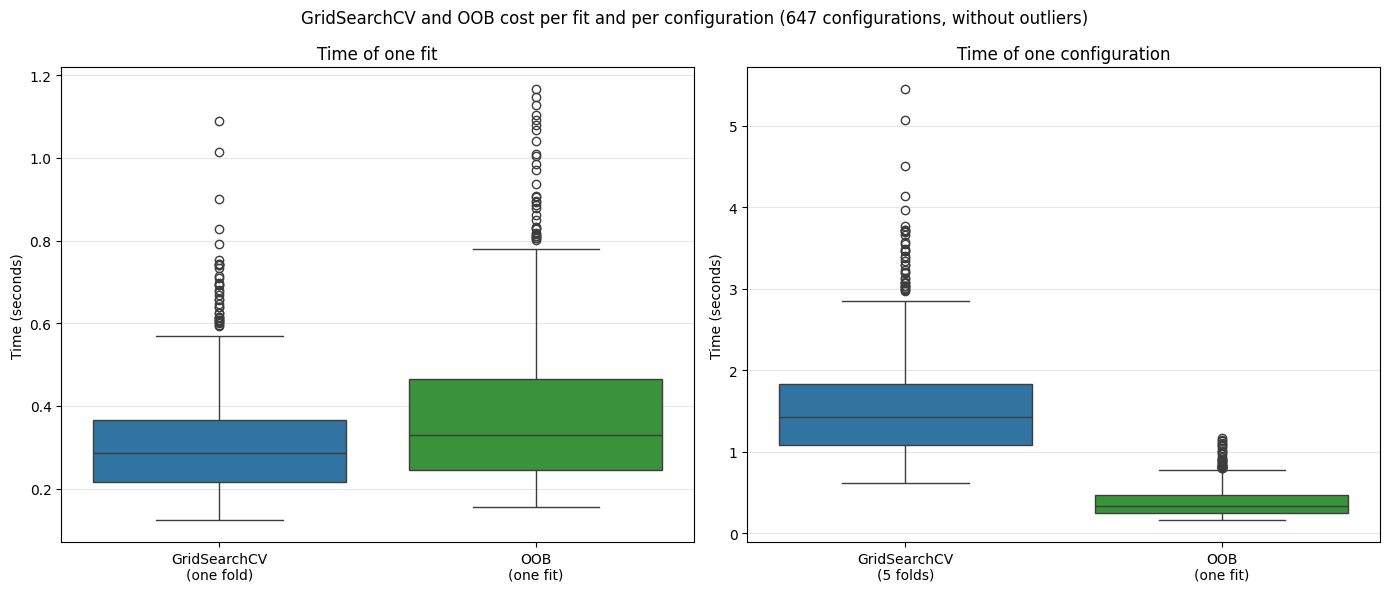

One fit: GridSearchCV (one fold)             0.2858
One fit: OOB                                 0.3302
One configuration: GridSearchCV (5 folds)    1.4289
One configuration: OOB                       0.3302
Name: median (s), dtype: float64


In [30]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(14, 6))

fit_time_df = pd.DataFrame({
    'GridSearchCV\n(one fold)': comparison_plot['grid_fold_time'],
    'OOB\n(one fit)': comparison_plot['oob_time'],
})
sns.boxplot(data=fit_time_df, palette=[paleta[0], paleta[2]], ax=ax[0])
ax[0].set_title('Time of one fit')
ax[0].set_ylabel('Time (seconds)')

config_time_df = pd.DataFrame({
    f'GridSearchCV\n({n_folds} folds)': comparison_plot['grid_config_time'],
    'OOB\n(one fit)': comparison_plot['oob_time'],
})
sns.boxplot(data=config_time_df, palette=[paleta[0], paleta[2]], ax=ax[1])
ax[1].set_title('Time of one configuration')
ax[1].set_ylabel('Time (seconds)')

for a in ax:
    a.grid(axis='y', alpha=0.3)
fig.suptitle(f'GridSearchCV and OOB cost per fit and per configuration ({len(comparison_plot)} configurations, without outliers)')
fig.tight_layout()
plt.show()

medians = pd.concat([fit_time_df.median(), config_time_df.median()]).round(4)
medians.index = ['One fit: GridSearchCV (one fold)', 'One fit: OOB',
                 f'One configuration: GridSearchCV ({n_folds} folds)', 'One configuration: OOB']
print(medians.rename('median (s)'))

The plot compares the time distribution of the 647 configurations shown (the 648 configurations minus the outlier described above) at two levels. In both panels, the Y axis shows the time in seconds, and each box corresponds to one strategy: blue for GridSearchCV and green for OOB.

**Left panel: time of one fit**
- One GridSearchCV fold has a median of **0.29 seconds**, and its box ranges from 0.22 to 0.37 seconds. The slowest fold took 1.09 seconds.
- One OOB fit has a median of **0.33 seconds**, and its box ranges from 0.25 to 0.47 seconds. The slowest fit took 1.17 seconds.
- The green box is higher and taller than the blue one: each OOB fit takes somewhat longer, and its time varies more across configurations. The isolated points in both boxes correspond to the most expensive configurations of the search space.

**Right panel: time of one configuration**
- When the 5 folds are added together, the GridSearchCV median rises to **1.43 seconds**, with configurations reaching 5.45 seconds.
- OOB keeps its median of 0.33 seconds, because each configuration is trained only once. The slowest OOB configuration (1.17 seconds) is faster than the GridSearchCV median.
- The middle 50% of GridSearchCV (1.08 to 1.83 seconds) lies well above the OOB box.

**Conclusion:** the plot confirms that OOB is slower per fit (median of 0.33 versus 0.29 seconds, 15.5% more), but much faster per configuration (0.33 versus 1.43 seconds, about 4.3 times less). The advantage of OOB does not come from faster training, but from avoiding the repeated fits of cross-validation.

#### **Plot 2. Total cost breakdown**

The total time of a search can be broken down as **number of fits × mean time per fit**. The plot shows these components in three bar panels, one per component, for each strategy:

- **Mean time per fit:** the average number of seconds taken by one GridSearchCV fold or one OOB fit.
- **Number of fits:** 648 × 5 + 1 in GridSearchCV (the folds plus the final refit) and 648 in OOB.
- **Total time:** the sum of the times of all fits. The total time measured with time.time(), which also includes the internal management of each search, is shown at the base of each bar.

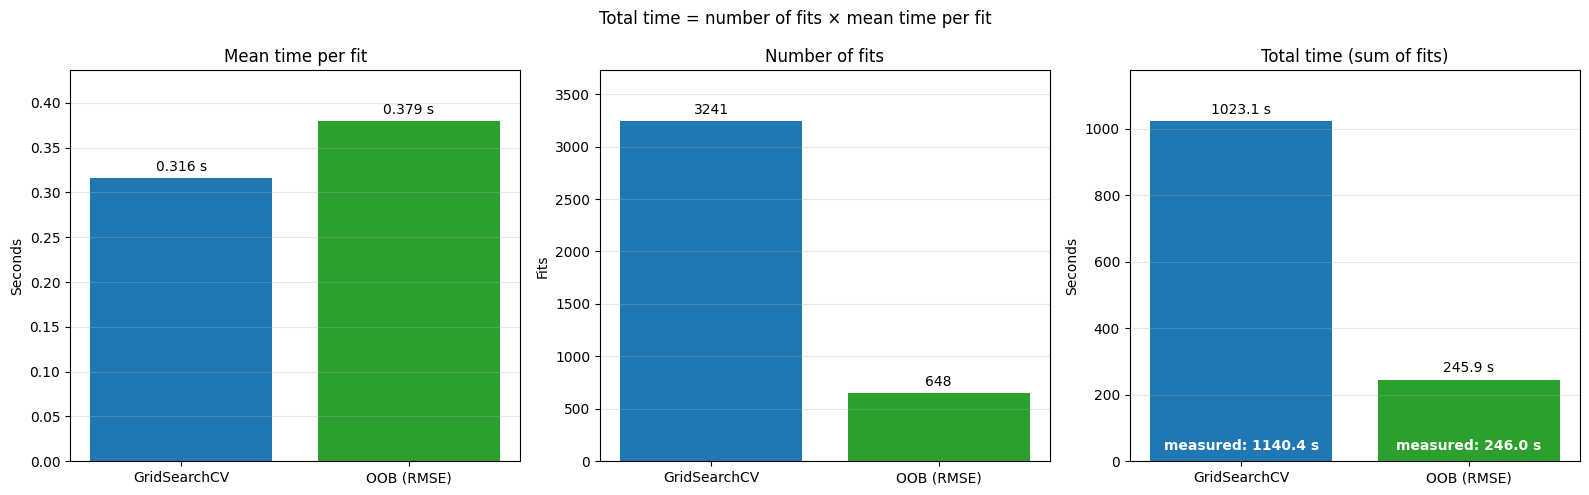

In [31]:
fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(16, 5))
colors = [paleta[0], paleta[2]]
methods = cost_summary.index

panels = [
    ('mean time per fit (s)', 'Mean time per fit', 'Seconds', '{:.3f} s'),
    ('fits', 'Number of fits', 'Fits', '{:.0f}'),
    ('sum of fits (s)', 'Total time (sum of fits)', 'Seconds', '{:.1f} s'),
]
for a, (column, title, label, fmt) in zip(ax, panels):
    bars = a.bar(methods, cost_summary[column], color=colors)
    a.bar_label(bars, labels=[fmt.format(v) for v in cost_summary[column]], padding=3)
    a.set_title(title)
    a.set_ylabel(label)
    a.margins(y=0.15)
    a.grid(axis='y', alpha=0.3)

for x, measured in enumerate(cost_summary['measured time (s)']):
    ax[2].annotate(f'measured: {measured:.1f} s', (x, 0), xytext=(0, 8),
                   textcoords='offset points', ha='center', color='white', fontweight='bold')

fig.suptitle('Total time = number of fits × mean time per fit')
fig.tight_layout()
plt.show()

The plot breaks down the total cost of each strategy into its two factors, with blue bars for GridSearchCV and green bars for OOB:

- **Mean time per fit (left panel):** OOB takes 0.379 seconds per fit and GridSearchCV 0.316. This is the only component in which OOB is more expensive.
- **Number of fits (center panel):** GridSearchCV performs 3,241 fits and OOB 648, that is, 5 times fewer. The proportion is set by cv=5.
- **Total time (right panel):** the sum of the fits is 1,023.1 seconds in GridSearchCV and 245.9 seconds in OOB. The measured time, shown at the base of each bar, is 1,140.4 and 246.0 seconds, respectively.

The total time is the product of the first two panels. GridSearchCV has a cheaper fit but repeats it 5 times per configuration. OOB has a fit that is 20.2% more expensive but performs it only once. The net result is that GridSearchCV took about 4.6 times longer than OOB according to the measured time (1,140.4 versus 246.0 seconds).

**Conclusion:** the cost of a hyperparameter search depends more on the number of fits than on the time of each fit. For this reason, a larger number of folds or a wider search space would increase the difference in favor of OOB.

## **Regression conclusions**
---
- **The OOB score reduced the search time by about 78%.** Evaluating the 648 configurations took 1,140.36 seconds with GridSearchCV and 245.98 seconds with OOB RMSE (244.64 with OOB R²).
- **OOB is slower per fit, but much faster per configuration.** One OOB fit took 0.379 seconds on average, 20.2% more than one GridSearchCV fold (0.316), because it trains on the 800 observations and calculates the out-of-bag predictions. However, GridSearchCV needed 3,241 fits compared with 648.
- **Predictive performance was almost the same.** The GridSearchCV model obtained a test RMSE of 2.3854 and the OOB model 2.4231: a difference of 0.04 units (1.6%).
- **The validation estimates of both strategies are at the same level.** The best mean cross-validation RMSE was 2.5505 and the best OOB RMSE was 2.5220, and both strategies selected very similar configurations (squared_error, log2, min_samples_leaf=1, and 200 trees).
- **OOB R² and OOB RMSE always select the same configuration.** With the same out-of-bag predictions, R² is a monotonic transformation of RMSE. The custom metric provides interpretability (the error in units of the target variable), not a different selection.
- **The relative gap did not improve selection.** The model with the smallest gap between training and validation (20.75%) obtained a test RMSE of 2.7992, 17.3% worse than GridSearchCV, and it required the same expensive search.
- **Limitations:** the results come from a synthetic dataset of 1,000 observations, a single test split of 200 observations, and a single machine. Times depend on the hardware and system load and may vary between runs; the proportions between strategies are more stable than the absolute values.

# **Info**
---

**@By:** Steven Bernal

**@Nickname:** Kaiziferr

**@Git:** https://github.com/Kaiziferr